# 03 · Quality audit of GHCN-Daily

**Question:** how far can you trust station weather data, and where does it break?

NOAA runs its own quality checks and records the outcome in a flag column. This notebook asks:

1. How much data is there, and how does coverage change over time?
2. How often does NOAA flag a value, and why?
3. Does an *independent* check find bad values NOAA did not flag?
4. How complete are station records, and where do they look like they changed?

Every audit is a Spark SQL file in `sql/`; the notebook runs it and plots the small result with pandas.

**Read this first: the sample is not random.** It is up to six stations per country, taken in station-id order, among stations with TMAX, TMIN and PRCP records starting by 1960 and still reporting in 2025. That makes early decades survivors by construction, so do not read the coverage numbers as global coverage.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from ghcnd_quality.spark import get_spark
from ghcnd_quality.audit import register_views, run_sql
from ghcnd_quality.dly import QFLAG_MEANING

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
spark = get_spark("nb03"); register_views(spark, "../data/parquet")

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=40689 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=40689 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/10 18:43:59 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/10 18:43:59 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/10/10 18:44:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1 · Coverage

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


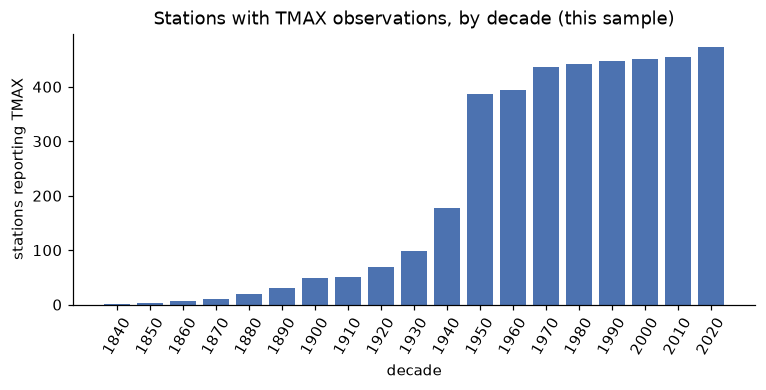

element,PRCP,SNOW,SNWD,TAVG,TMAX,TMIN
decade,,,,,,
1830,1,0,0,0,0,0
1840,1,0,0,0,1,1
1850,5,0,0,0,3,3
1860,7,0,0,0,6,6
1870,11,0,0,0,11,11
1880,20,0,3,3,20,22
1890,32,1,6,4,31,35
1900,56,1,11,4,48,50
1910,65,2,12,4,51,55


In [2]:
cov = run_sql(spark, "01_coverage")
tmax = cov[cov.element == "TMAX"]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(tmax.decade.astype(str), tmax.stations, color="#4C72B0")
ax.set_ylabel("stations reporting TMAX"); ax.set_xlabel("decade"); plt.xticks(rotation=60)
ax.set_title("Stations with TMAX observations, by decade (this sample)"); plt.show()
cov.pivot(index="decade", columns="element", values="stations").fillna(0).astype(int)

## 2 · How often does NOAA flag a value?

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


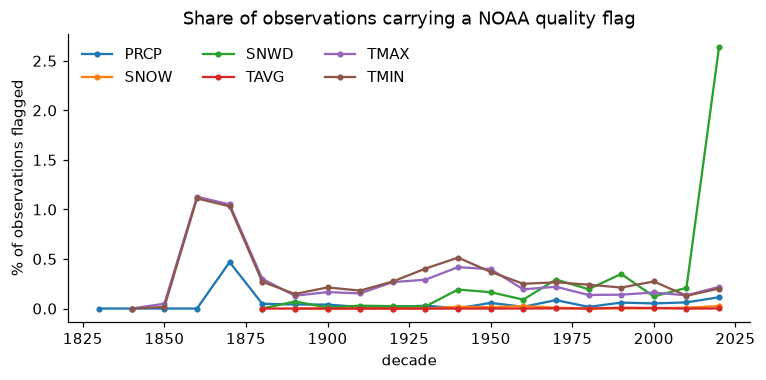

element,PRCP,SNOW,SNWD,TAVG,TMAX,TMIN
decade,,,,,,
1830,0.000,NaN,NaN,NaN,NaN,NaN
1840,0.000,NaN,NaN,NaN,0.000,0.000
1850,0.000,NaN,NaN,NaN,0.049,0.016
1860,0.000,NaN,NaN,NaN,1.129,1.111
1870,0.469,NaN,NaN,NaN,1.051,1.032
1880,0.048,NaN,0.000,0.000,0.301,0.271
1890,0.041,0.000,0.071,0.000,0.129,0.147
1900,0.040,0.000,0.011,0.000,0.166,0.213
1910,0.016,0.000,0.029,0.000,0.153,0.181


In [3]:
rates = run_sql(spark, "02_flag_rates")
fig, ax = plt.subplots(figsize=(8, 3.4))
for el, g in rates.groupby("element"):
    ax.plot(g.decade, g.pct_flagged, marker="o", ms=3, label=el)
ax.set_ylabel("% of observations flagged"); ax.set_xlabel("decade"); ax.legend(frameon=False, ncol=3)
ax.set_title("Share of observations carrying a NOAA quality flag"); plt.show()
rates.pivot(index="decade", columns="element", values="pct_flagged")

Which checks fire? (`qflag` letters are decoded in `ghcnd_quality.dly.QFLAG_MEANING`.)

In [4]:
reasons = run_sql(spark, "03_flag_reasons")
reasons["meaning"] = reasons.qflag.map(QFLAG_MEANING)
reasons.head(12)

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,qflag,element,flagged,pct_of_element_flags,meaning
0,I,TMIN,19278,76.6,failed internal consistency check
1,I,TMAX,14105,69.2,failed internal consistency check
2,D,TMAX,2833,13.9,failed duplicate check
3,D,TMIN,2518,10.0,failed duplicate check
4,O,TMAX,1957,9.6,failed climatological outlier check
5,X,SNWD,1732,27.5,failed bounds check
6,O,TMIN,1654,6.6,failed climatological outlier check
7,K,PRCP,1625,33.4,failed streak / frequent-value check
8,D,PRCP,1573,32.4,failed duplicate check
9,K,SNWD,1504,23.9,failed streak / frequent-value check


## 3 · Do independent checks find what NOAA missed?

Rules from physical limits: TMAX above 57 °C or TMIN below -90 °C (close to the record highs and lows ever measured on Earth), more than 1,900 mm of rain in one day, negative amounts, and a daily maximum below the same day's minimum. For each rule: how many observations break it, and how many NOAA had already flagged.

In [5]:
bad = run_sql(spark, "04_implausible_values", tmax_max=57.0, tmin_min=-90.0, prcp_max=1900.0)
bad

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,rule,violations,flagged_by_noaa,unflagged
0,TMAX below TMIN (same day),7309,7309,0
1,negative PRCP/SNOW/SNWD,1830,1830,0
2,TMAX above bound,209,209,0
3,TMIN below bound,47,47,0
4,PRCP above bound,1,1,0


In [6]:
unflagged = int(bad.unflagged.sum())
print(f"{int(bad.violations.sum()):,} violations across all rules; {unflagged:,} not flagged by NOAA")
if unflagged == 0:
    print("NOAA's flags already cover every gross error these rules can find. The independent check adds nothing here.")

9,396 violations across all rules; 0 not flagged by NOAA
NOAA's flags already cover every gross error these rules can find. The independent check adds nothing here.


That covers gross errors. A subtler failure is a sensor stuck on one reading. Find runs of at least 10 consecutive days where a station reports the identical TMAX, TMIN or TAVG, and see how many of those days NOAA flagged:

In [7]:
runs = run_sql(spark, "05_repeated_values", min_run=10)
runs["bucket"] = pd.cut(runs.run_days, [0, 14, 29, 10**6], labels=["10-14 days", "15-29 days", "30+ days"])
summary = (runs.groupby(["element", "bucket"], observed=True)
               .agg(runs=("run_days", "size"), days=("run_days", "sum"), flagged_days=("flagged_days", "sum")))
summary["pct_days_flagged"] = (100 * summary.flagged_days / summary.days).round(1)
summary

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


runs  days  flagged_days  pct_days_flagged
element bucket                                                
TAVG    10-14 days     3    31             0               0.0
TMAX    10-14 days   165  1808            38               2.1
        15-29 days    34   629           305              48.5
        30+ days      10   713           712              99.9
TMIN    10-14 days    73   811            61               7.5
        15-29 days    33   603           340              56.4
        30+ days      11   445           445             100.0

The longest runs, with where and what value:

In [8]:
runs.head(12)[["station_id", "name", "element", "value_c", "run_days", "flagged_days", "start_date", "end_date"]]

,station_id,name,element,value_c,run_days,flagged_days,start_date,end_date
0,FI000000304,HELSINKI KAISANIEMI AWS,TMAX,0.000000,367,366,1952-01-01,1953-01-01
1,RP000982230,LAOAG,TMAX,-2.000000,100,100,1961-10-01,1962-01-08
2,RP000982230,LAOAG,TMIN,-2.000000,100,100,1961-10-01,1962-01-08
3,FMC00914395,KOSRAE,TMIN,23.900000,56,56,1963-12-22,1964-02-15
4,USC00010178,ALICEVILLE,TMIN,11.100000,44,44,2005-05-15,2005-06-27
5,RP000982230,LAOAG,TMAX,-2.000000,31,31,1998-05-01,1998-05-31
6,RP000098836,ZAMBOANGA,TMAX,-2.000000,31,31,1979-01-01,1979-01-31
7,RP000098836,ZAMBOANGA,TMAX,-2.000000,31,31,1989-12-01,1989-12-31
8,RP000098836,ZAMBOANGA,TMAX,-2.000000,31,31,1998-05-01,1998-05-31
9,RP000982230,LAOAG,TMIN,-2.000000,31,31,1998-05-01,1998-05-31


Which values repeat most often across stations?

In [9]:
runs.value_c.value_counts().head(8).rename("runs with this value").to_frame().rename_axis("value_c")

,runs with this value
value_c,
23.900000,44
30.000000,38
31.100000,25
-2.000000,21
29.400000,20
32.200000,18
30.600000,16
31.700000,15


In [10]:
# Many of the repeated values are whole degrees Fahrenheit (75 F = 23.9 C, 86 F = 30.0 C): stations that
# report to the nearest degree F repeat values naturally. Test that instead of assuming it.
f = runs.value_c * 9 / 5 + 32
runs["whole_f"] = (f - f.round()).abs() < 0.06
runs.groupby("bucket", observed=True).agg(runs=("whole_f", "size"), pct_whole_f=("whole_f", lambda s: round(100 * s.mean(), 1)))

,runs,pct_whole_f
bucket,,
10-14 days,241,58.1
15-29 days,67,68.7
30+ days,21,19.0


The short runs are mostly whole-degree Fahrenheit reporters repeating a plausible value, so they are weak evidence of a fault; NOAA leaves most of them alone. The long runs are different: almost every day is flagged. Runs of a value that is *not* a whole degree F (for example -2.0 C, repeated for months at several Philippine stations) are the clearest stuck-sensor cases.

## 4 · Completeness and station changes

Completeness for TMAX: every year strictly between a station's first and last observation, scored as observed days over days in the year. A year with no data at all counts as zero. The first and last years are excluded because they are partial by construction (a station opening in June, or the current year not being over).

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


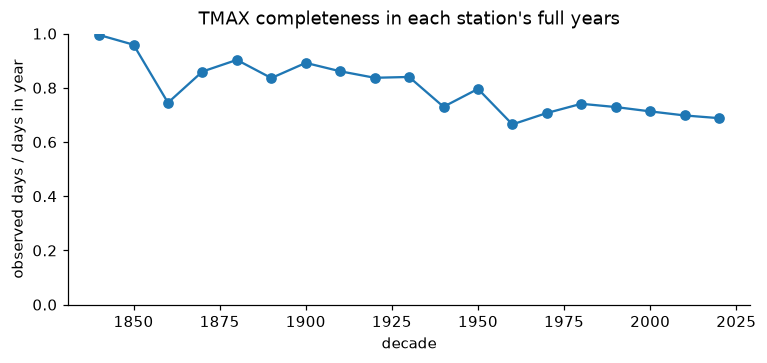

,decade,station_years,mean_completeness,pct_empty_years,pct_under_90
0,1840,5,0.995,0.0,0.0
1,1850,16,0.959,0.0,12.5
2,1860,37,0.745,24.3,29.7
3,1870,79,0.860,12.7,15.2
4,1880,169,0.903,8.3,11.2
5,1890,254,0.836,13.4,20.1
6,1900,428,0.892,8.4,14.3
7,1910,518,0.861,9.7,18.3
8,1920,613,0.837,13.1,20.9
9,1930,860,0.840,10.7,24.1


In [11]:
comp = run_sql(spark, "06_completeness")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(comp.decade, comp.mean_completeness.astype(float), marker="o", label="mean completeness")
ax.set_ylim(0, 1); ax.set_ylabel("observed days / days in year"); ax.set_xlabel("decade")
ax.set_title("TMAX completeness in each station's full years"); plt.show()
comp

Annual mean TMAX at one station should not jump by several degrees from one well-observed year to the next. Steps this large are candidates for a station move, an instrument change, or a data problem (heuristic, not proof):

In [12]:
jumps = run_sql(spark, "07_annual_mean_jumps", min_days=330, jump_c=3.0)
print(f"{len(jumps)} year-to-year steps of 3 C or more, across {jumps.station_id.nunique()} stations")
jumps.head(10)

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


72 year-to-year steps of 3 C or more, across 43 stations


,station_id,prev_year,year,prev_mean_tmax,mean_tmax,step_c
0,MXM00076342,1972,1973,30.16,24.97,-5.19
1,RSM00020069,2012,2013,-4.01,-8.90,-4.89
2,RSM00020667,1958,1959,-9.75,-4.97,4.78
3,GL000004250,1984,1985,-0.77,3.70,4.48
4,RSM00020476,2012,2013,-5.77,-10.15,-4.38
5,MXM00076342,1973,1974,24.97,29.28,4.31
6,GG000037395,2010,2011,22.89,18.74,-4.16
7,SF000068858,2000,2001,23.60,19.53,-4.07
8,RQC00660158,2002,2003,25.99,21.95,-4.05
9,CHM00050915,1955,1956,10.43,6.41,-4.02


A permanent change (a station move) shows up as one step. A single bad year shows up as a step *and* a step back. Count how many of the jumps are immediately reversed (the rest are either persistent shifts or genuinely unusual years; this heuristic cannot tell them apart):

In [13]:
j = jumps.sort_values(["station_id", "year"]).copy()
j["next_year_step"] = j.groupby("station_id").step_c.shift(-1)
j["next_year"] = j.groupby("station_id").year.shift(-1)
j["reversed_next_year"] = (j.next_year == j.year + 1) & (j.next_year_step * j.step_c < 0)
print(f"{j.reversed_next_year.sum()} of {len(j)} jumps are followed by a jump back the next year "
      f"({j.reversed_next_year.mean():.0%}); the rest stay at the new level or keep moving")
j[j.reversed_next_year].head(5)[["station_id", "year", "step_c", "next_year_step"]]

3 of 72 jumps are followed by a jump back the next year (4%); the rest stay at the new level or keep moving


,station_id,year,step_c,next_year_step
0,MXM00076342,1973,-5.19,4.31
21,ROE00100829,1934,3.63,-3.07
2,RSM00020667,1959,4.78,-3.83


## Summary

In [14]:
tot_obs = int(rates.observations.sum()); tot_flag = int(rates.flagged.sum())
print(f"{tot_obs:,} observations; NOAA flagged {tot_flag:,} ({100 * tot_flag / tot_obs:.2f}%)")
top = reasons.groupby("qflag").flagged.sum().sort_values(ascending=False).head(3)
print("most common flags:", ", ".join(f"{k} ({QFLAG_MEANING[k]})" for k in top.index))
print(f"independent bounds checks found {unflagged:,} violations NOAA had not flagged")
rr = runs[runs.element.isin(['TMAX', 'TMIN'])]
print(f"stuck-value runs (>=10 days, TMAX/TMIN): {len(rr)}; "
      f"{100 * rr.flagged_days.sum() / rr.run_days.sum():.1f}% of their days flagged by NOAA")
print(f"mean TMAX completeness in full station-years, 2010s: {comp.mean_completeness.astype(float).iloc[-2]:.2f}")
spark.stop()

39,358,220 observations; NOAA flagged 56,962 (0.14%)
most common flags: I (failed internal consistency check), D (failed duplicate check), O (failed climatological outlier check)
independent bounds checks found 0 violations NOAA had not flagged
stuck-value runs (>=10 days, TMAX/TMIN): 326; 38.0% of their days flagged by NOAA
mean TMAX completeness in full station-years, 2010s: 0.70
